# Job Market Skills & Salary Analytics

**Objective:** Analyse job-posting demand, skills, locations, experience and disclosed salary ranges using Python. This is a descriptive analysis of the supplied dataset, not a guarantee of the whole Indian labour market.

**Dataset:** `data/raw/indian-job-market-dataset-2025.xlsx` (97,929 rows; 17 columns in the provided file).

**Run order:** Execute cells from top to bottom. The notebook exports cleaned analytical data and CSV summaries to `outputs/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
# If notebook is opened from the notebooks folder, move to project root.
if not (ROOT / "data" / "raw").exists() and (ROOT.parent / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "indian-job-market-dataset-2025.xlsx"
OUTPUT_DIR = ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

df = pd.read_excel(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 97,929 | Columns: 17


## 1. Understand the dataset

In [2]:
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_count": df.isna().sum(), "missing_pct": (df.isna().mean()*100).round(2), "unique_values": df.nunique(dropna=True)}))
display(df.describe(include="all").T)

,title,jobId,currency,jobUploaded,companyName,tagsAndSkills,experience,salary,location,companyId,ReviewsCount,AggregateRating,jobDescription,minimumSalary,maximumSalary,minimumExperience,maximumExperience
0,Sr. HR Recruiter (NON IT),270925008041,INR,6 Days Ago,Orion,"Communication,Manpower,Staffing,Convincing Pow...",2-4 Yrs,2-4 Lacs PA,Kolkata(Chinar Park),645563,NaN,NaN,Preferred candidate profile . .,200000.0,400000.0,2.0,4.0
1,Fire And Safety Officer,270925007584,INR,6 Days Ago,"Apollo Hospitals International Limited, Ahmedabad","Safety Officer Activities,Fire Protection,Fire...",6-11 Yrs,3-5 Lacs PA,"Gandhinagar, Ahmedabad",14072,5162.0,4.0,"Ensure active Fire Protection System,such as F...",300000.0,500000.0,6.0,11.0
2,Opening For Performance Marketing - Chennai,270925007492,INR,6 Days Ago,TVS Credit Services Ltd,"Performance Marketing,User Acquisition,growth ...",12-18 Yrs,Not disclosed,Chennai,1324750,2892.0,4.2,MBA Marketing (preferred Tier II or III B- Sch...,0.0,0.0,12.0,18.0
3,Medical Billing Executive,270925007443,INR,6 Days Ago,GNR Global Services,"Fluent English,Spoken English,Good English Com...",0-3 Yrs,"70,000-2 Lacs PA","Mohali, Chandigarh, Kharar, Zirakpur",123804403,NaN,NaN,Job Title-Medical Billing Executive\nLocation-...,70000.0,200000.0,0.0,3.0
4,Senior Group Product Manager - CNS Therapy,270925007430,INR,6 Days Ago,Cadila Pharmaceuticals,"Product Marketing,CNS,Product Management,Nephr...",5-10 Yrs,8-18 Lacs PA,Ahmedabad,14957,2134.0,3.4,Principal Tasks & Responsibilities : (Please w...,800000.0,1800000.0,5.0,10.0


,dtype,missing_count,missing_pct,unique_values
title,object,0,0.00,55104
jobId,int64,0,0.00,97679
currency,object,0,0.00,2
jobUploaded,object,0,0.00,30
companyName,object,4,0.00,18668
tagsAndSkills,object,571,0.58,84307
experience,object,2105,2.15,287
salary,object,0,0.00,1339
location,object,0,0.00,10066
companyId,int64,0,0.00,18328


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,97929,55104,Application Developer,2039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jobId,97929.0,NaN,NaN,NaN,206985423051.857239,99878601476.771545,10125001764.0,180825009352.0,250825003714.0,280825021346.0,311224008927.0
currency,97929,2,INR,97800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jobUploaded,97929,30,4 Days Ago,13973,NaN,NaN,NaN,NaN,NaN,NaN,NaN
companyName,97925,18668,Accenture,8204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tagsAndSkills,97358,84307,"Retail,Lead generation,Forex,Investment produc...",116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience,95824,287,5-10 Yrs,6448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,97929,1339,Not disclosed,64076,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,97929,10066,Bengaluru,16823,NaN,NaN,NaN,NaN,NaN,NaN,NaN
companyId,97929.0,NaN,NaN,NaN,27846420.597821,49791844.09429,3.0,233939.0,2892790.0,6398332.0,125142239.0


## 2. Data quality checks

In [3]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate job IDs:", df["jobId"].duplicated().sum())
print("Currency counts:")
display(df["currency"].value_counts(dropna=False))
print("Salary disclosure labels:")
display(df["salary"].value_counts(dropna=False).head(10))
print("Numeric salary bounds equal to zero:", int(((df["minimumSalary"] == 0) & (df["maximumSalary"] == 0)).sum()))

Exact duplicate rows: 247
Duplicate job IDs: 250
Currency counts:


currency
INR    97800
USD      129
Name: count, dtype: int64

Salary disclosure labels:


salary
Not disclosed    64076
3-5 Lacs PA        584
3-6 Lacs PA        549
3-4 Lacs PA        497
2-3 Lacs PA        472
2-4 Lacs PA        437
4-6 Lacs PA        435
10-20 Lacs PA      381
15-25 Lacs PA      379
3-4.5 Lacs PA      374
Name: count, dtype: int64

Numeric salary bounds equal to zero: 64121


## 3. Clean and prepare data

In [4]:
jobs = df.copy()
# Trim text fields without changing the raw source file.
text_cols = ["title", "companyName", "location", "currency", "salary", "experience", "tagsAndSkills", "jobUploaded"]
for col in text_cols:
    if col in jobs.columns:
        jobs[col] = jobs[col].astype("string").str.strip()

# One row per job ID; keep the first occurrence and report the number removed.
rows_before = len(jobs)
jobs = jobs.drop_duplicates(subset="jobId", keep="first").copy()
print("Duplicate job IDs removed:", rows_before - len(jobs))

# Missing skill tags are labelled, not guessed.
jobs["tagsAndSkills"] = jobs["tagsAndSkills"].fillna("Not Specified")

# 0/0 salary bounds represent undisclosed salaries in this file. Keep source columns,
# but use NaN in derived analysis fields so zeros do not distort salary statistics.
for col in ["minimumSalary", "maximumSalary", "minimumExperience", "maximumExperience"]:
    jobs[col] = pd.to_numeric(jobs[col], errors="coerce")

jobs["salary_available"] = (
    jobs["minimumSalary"].gt(0) & jobs["maximumSalary"].gt(0) & jobs["currency"].eq("INR")
)
jobs["salary_midpoint_inr"] = np.where(
    jobs["salary_available"], (jobs["minimumSalary"] + jobs["maximumSalary"]) / 2, np.nan
)
jobs["salary_midpoint_lpa"] = jobs["salary_midpoint_inr"] / 100000
jobs["experience_midpoint_years"] = np.where(
    jobs["minimumExperience"].notna() & jobs["maximumExperience"].notna(),
    (jobs["minimumExperience"] + jobs["maximumExperience"]) / 2, np.nan
)
print("Rows after deduplication:", f"{len(jobs):,}")
print("INR jobs with disclosed numeric salary:", f"{int(jobs['salary_available'].sum()):,}")
display(jobs[["title", "currency", "salary", "minimumSalary", "maximumSalary", "salary_midpoint_lpa"]].head())

Duplicate job IDs removed: 250
Rows after deduplication: 97,679
INR jobs with disclosed numeric salary: 33,116


,title,currency,salary,minimumSalary,maximumSalary,salary_midpoint_lpa
0,Sr. HR Recruiter (NON IT),INR,2-4 Lacs PA,200000.0,400000.0,3.00
1,Fire And Safety Officer,INR,3-5 Lacs PA,300000.0,500000.0,4.00
2,Opening For Performance Marketing - Chennai,INR,Not disclosed,0.0,0.0,NaN
3,Medical Billing Executive,INR,"70,000-2 Lacs PA",70000.0,200000.0,1.35
4,Senior Group Product Manager - CNS Therapy,INR,8-18 Lacs PA,800000.0,1800000.0,13.00


## 4. Job demand: titles, companies and location labels

,title,job_postings
0,Application Developer,2033
1,Application Lead,1346
2,Sales Executive,576
3,Software Development Engineer,497
4,Business Development Executive,456
5,Trust & Safety New Associate,348
6,Data Engineer,338
7,Business Development Manager,323
8,Sales Manager,319
9,Java Full Stack Developer,282


,company,job_postings
0,Accenture,8193
1,IDESLABS PRIVATE LIMITED,2294
2,Wipro,1494
3,Krazy Mantra HR Solutions Pvt. Ltd,1026
4,PRO Hr Complete Solutions,981
5,Kotak Mahindra Bank,980
6,Infosys,937
7,Capgemini,698
8,IBM,687
9,PRADEEPIT CONSULTING SERVICES PVT LTD,615


,location,job_postings
0,Bengaluru,16783
1,Hyderabad,7657
2,Pune,6096
3,Chennai,4418
4,Gurugram,4226
5,Mumbai,4149
6,Noida,2688
7,Remote,1952
8,Ahmedabad,1721
9,Navi Mumbai,1451


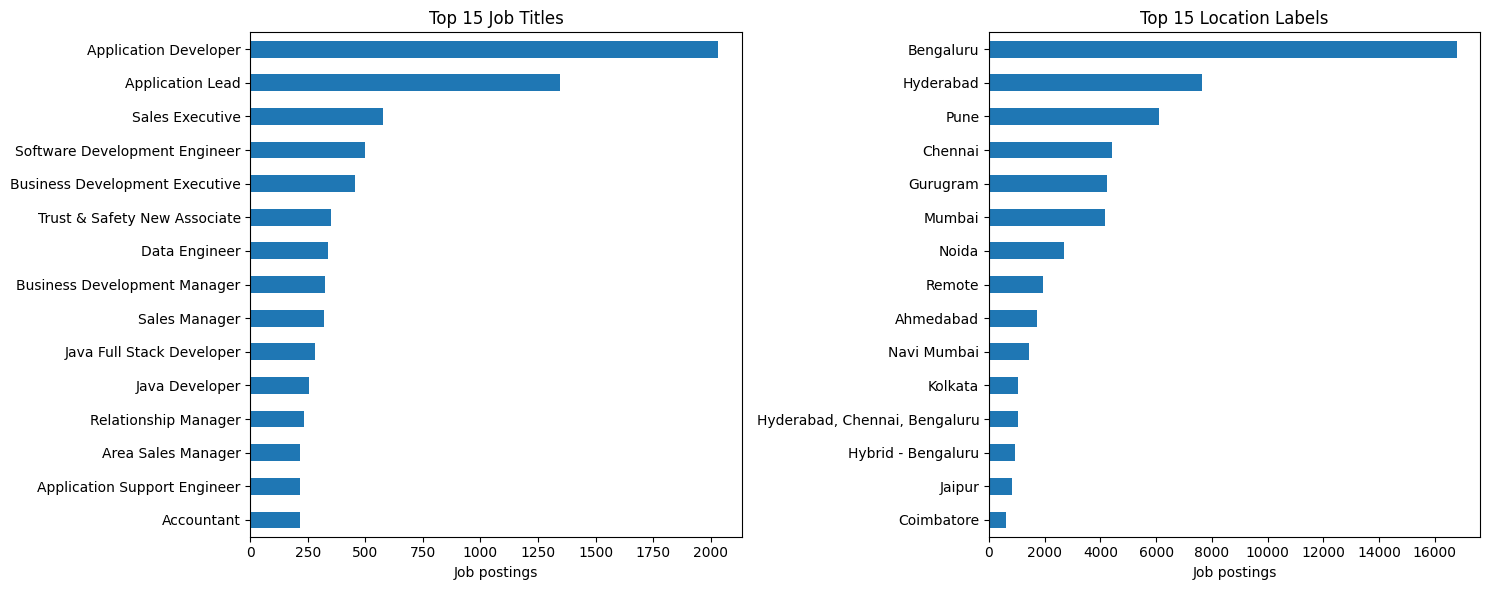

In [5]:
top_titles = jobs["title"].value_counts().head(15).rename_axis("title").reset_index(name="job_postings")
top_companies = jobs["companyName"].value_counts().head(15).rename_axis("company").reset_index(name="job_postings")
top_locations = jobs["location"].value_counts().head(15).rename_axis("location").reset_index(name="job_postings")
display(top_titles.head(10))
display(top_companies.head(10))
display(top_locations.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_titles.sort_values("job_postings").plot(kind="barh", x="title", y="job_postings", legend=False, ax=axes[0], title="Top 15 Job Titles")
top_locations.sort_values("job_postings").plot(kind="barh", x="location", y="job_postings", legend=False, ax=axes[1], title="Top 15 Location Labels")
axes[0].set_xlabel("Job postings"); axes[0].set_ylabel("")
axes[1].set_xlabel("Job postings"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "job_demand_overview.png", dpi=160); plt.show()

## 5. Skill demand

`tagsAndSkills` contains comma-separated tags. This section splits those tags into individual skills and counts each skill once per job posting. Skill spelling variants are lowercased, but synonyms are not merged (for example, `power bi` and `powerbi` may remain separate).

,skill,job_postings
0,sales,9178
1,python,5846
2,project management,5543
3,customer service,5122
4,sap,5043
5,management,4849
6,css,4186
7,java,4088
8,sql,3983
9,business development,3738


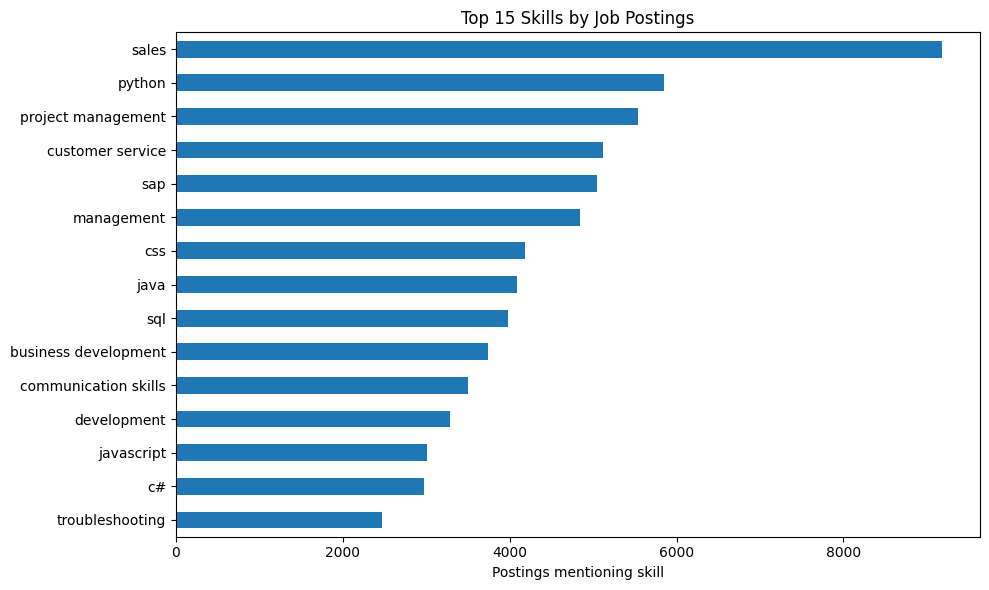

In [6]:
skill_records = []
for job_id, tags in jobs.loc[jobs["tagsAndSkills"].ne("Not Specified"), ["jobId", "tagsAndSkills"]].itertuples(index=False, name=None):
    skill_set = {s.strip().lower() for s in str(tags).split(",") if s.strip()}
    skill_records.extend((job_id, skill) for skill in skill_set)
skill_jobs = pd.DataFrame(skill_records, columns=["jobId", "skill"])
skill_demand = (skill_jobs.groupby("skill")["jobId"].nunique().sort_values(ascending=False).head(20).reset_index(name="job_postings"))
display(skill_demand.head(15))
ax = skill_demand.head(15).sort_values("job_postings").plot(kind="barh", x="skill", y="job_postings", legend=False, figsize=(10, 6), title="Top 15 Skills by Job Postings")
ax.set_xlabel("Postings mentioning skill"); ax.set_ylabel(""); plt.tight_layout(); plt.savefig(FIGURE_DIR / "top_skills.png", dpi=160); plt.show()

## 6. Salary analysis

INR postings with usable salary: 33,116
Share of cleaned postings: 33.9%


,salary_midpoint_lpa
count,33116.00
mean,7.58
std,10.26
min,0.01
25%,2.88
50%,4.25
75%,8.25
max,825.00


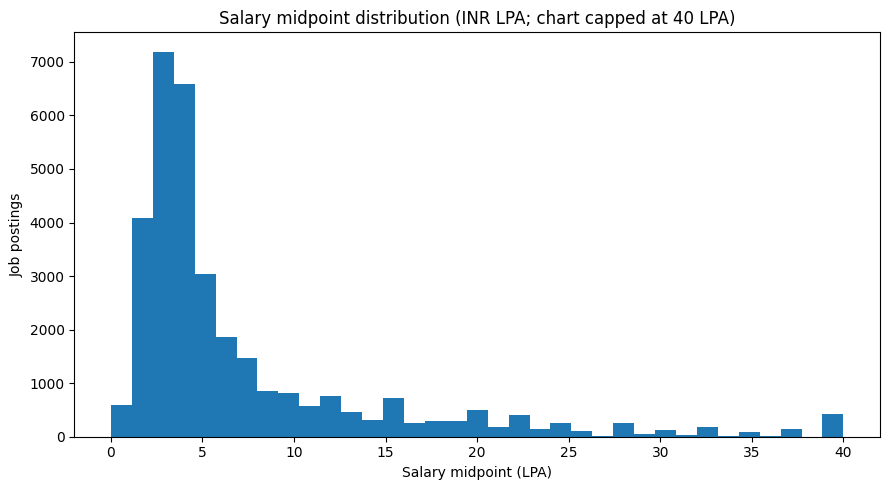

In [7]:
salary_jobs = jobs.dropna(subset=["salary_midpoint_lpa"]).copy()
print("INR postings with usable salary:", f"{len(salary_jobs):,}")
print("Share of cleaned postings:", f"{len(salary_jobs)/len(jobs)*100:.1f}%")
display(salary_jobs["salary_midpoint_lpa"].describe().to_frame("salary_midpoint_lpa").round(2))

# Clip only for chart readability; summary statistics above use the un-clipped data.
plt.figure(figsize=(9, 5))
plt.hist(salary_jobs["salary_midpoint_lpa"].clip(upper=40), bins=35)
plt.title("Salary midpoint distribution (INR LPA; chart capped at 40 LPA)")
plt.xlabel("Salary midpoint (LPA)"); plt.ylabel("Job postings")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "salary_distribution.png", dpi=160); plt.show()

## 7. Salary by role and experience

,title,job_postings,median_salary_lpa
0,Data Solution Architect,37,25.000
1,Solution Architect,59,25.000
2,Data Architect,12,23.750
3,Senior Software Engineer,22,22.500
4,Data Scientist,23,22.500
5,Senior Java Developer,19,22.250
6,Python Developer Lead,10,21.250
7,Site Reliability Engineer,14,20.000
8,Senior Data Engineer,40,20.000
9,Big Data Engineer,59,20.000


,experience_band,job_postings,median_salary_lpa
0,0–1,3017,2.25
1,1–3,10936,3.25
2,3–5,7801,4.20
3,5–10,8483,8.75
4,10–15,2166,15.00
5,15+,713,25.00


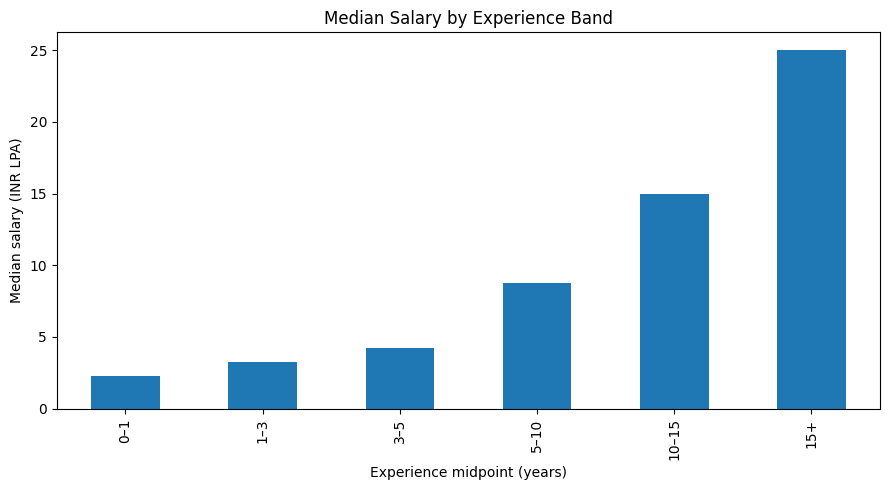

In [8]:
salary_by_title = (salary_jobs.groupby("title").agg(
    job_postings=("jobId", "nunique"), median_salary_lpa=("salary_midpoint_lpa", "median")
).query("job_postings >= 10").sort_values("median_salary_lpa", ascending=False).reset_index())
display(salary_by_title.head(15))

exp_jobs = salary_jobs.dropna(subset=["experience_midpoint_years"]).copy()
exp_jobs = exp_jobs[exp_jobs["experience_midpoint_years"].between(0, 40)]
exp_jobs["experience_band"] = pd.cut(
    exp_jobs["experience_midpoint_years"], bins=[-0.01, 1, 3, 5, 10, 15, 40],
    labels=["0–1", "1–3", "3–5", "5–10", "10–15", "15+"]
)
salary_by_experience = exp_jobs.groupby("experience_band", observed=False).agg(
    job_postings=("jobId", "nunique"), median_salary_lpa=("salary_midpoint_lpa", "median")
).reset_index()
display(salary_by_experience)
ax = salary_by_experience.plot(kind="bar", x="experience_band", y="median_salary_lpa", legend=False, figsize=(9,5), title="Median Salary by Experience Band")
ax.set_xlabel("Experience midpoint (years)"); ax.set_ylabel("Median salary (INR LPA)"); plt.tight_layout(); plt.savefig(FIGURE_DIR / "salary_by_experience.png", dpi=160); plt.show()

## 8. Skills associated with salary

In [9]:
skill_salary_records = skill_jobs.merge(salary_jobs[["jobId", "salary_midpoint_lpa"]], on="jobId", how="inner")
skill_salary = skill_salary_records.groupby("skill").agg(
    salary_postings=("jobId", "nunique"), median_salary_lpa=("salary_midpoint_lpa", "median")
).reset_index()
# Minimum sample size reduces misleading results from skills seen in only a few salary-disclosed jobs.
skill_salary = skill_salary.query("salary_postings >= 50").sort_values("median_salary_lpa", ascending=False)
display(skill_salary.head(15))
print("Interpretation caution: association is not proof that a skill itself causes a higher salary.")

,skill,salary_postings,median_salary_lpa
7271,dnb,103,30.000
19793,radiology,54,28.725
10243,general medicine,63,27.500
8183,encryption,53,25.000
6318,data architecture,58,25.000
6452,database,75,25.000
16466,nosql,61,25.000
6383,data modeling,94,25.000
5515,core banking,54,25.000
6533,dbms,65,24.500


Interpretation caution: association is not proof that a skill itself causes a higher salary.


## 9. Export project outputs

In [10]:
export_cols = [
    "title", "jobId", "currency", "jobUploaded", "companyName", "tagsAndSkills", "experience", "salary", "location",
    "companyId", "ReviewsCount", "AggregateRating", "minimumSalary", "maximumSalary", "minimumExperience",
    "maximumExperience", "salary_available", "salary_midpoint_lpa", "experience_midpoint_years"
]
jobs[export_cols].to_csv(OUTPUT_DIR / "cleaned_jobs.csv", index=False)
skill_demand.to_csv(OUTPUT_DIR / "skill_demand.csv", index=False)
salary_by_title.to_csv(OUTPUT_DIR / "salary_by_job_title.csv", index=False)
salary_by_experience.to_csv(OUTPUT_DIR / "salary_by_experience.csv", index=False)
top_titles.to_csv(OUTPUT_DIR / "top_job_titles.csv", index=False)
top_companies.to_csv(OUTPUT_DIR / "top_companies.csv", index=False)
top_locations.to_csv(OUTPUT_DIR / "top_locations.csv", index=False)
print("Exports saved to:", OUTPUT_DIR.resolve())

Exports saved to: /mnt/data/Job_Market_Skills_Salary_Analytics/outputs


## 10. Findings and limitations

Write your final 4–6 insights after running the notebook. Do not treat these listings as a complete census of all jobs in India.

- Salary analysis includes only rows with positive numeric salary bounds and `currency == INR`.
- `jobUploaded` is relative text (for example, “6 Days Ago”), not a verified calendar date; do not use it as an exact time series without additional parsing and validation.
- Locations may contain multiple cities or work-mode labels; the location chart counts raw labels, not standardized cities.
- Skill tags are noisy and may contain spelling variants or near-duplicates.
- Missing company reviews/ratings are not filled with zero.
- Median salary is used because salary distributions can be skewed; the salary midpoint is an estimate from the minimum and maximum bounds.